# Fig. 2: quasiparticle interference at the domain walls and its tight-binding counterpart


    Panels **a, b**: a line section through the grid spectroscopy map of Fig. 1 (along the dashed line
    of Fig. 1e), and its derivative along the sample bias.
    Panel **c**: the scattering wave vectors read off the line spectrum of panel d, overlaid on the
    tight-binding band structure of the (+⁴−) stacking.
    Panel **d**: the derivative of a line spectrum measured across a single domain wall.
    Panels **e, f**: tight-binding LDOS along a line across the (+⁴−) region embedded in (+⁵), and
    its energy derivative.

    Data: `MK_ABC_FLG_25_9K_2023_10_31_08_48_27_991.sm4` (grid), `MK_ABC_FLG_25_9K_2023_10_28_05_15_50_267.sm4`
    (line spectrum), the TB bands `l_6_1b_relevant_bands.npy` with their k axis `linear_k.npy`, and the TB
    line spectrum of system 1 (`x_1_MARCI.txt`, `ldos_1_MARCI.txt.gz`, `TB_LS_E.txt`).


Paper: Kandrai, K. *et al.* One-way electron mirrors from single-layer stacking shifts in rhombohedral graphite. Preprint at https://arxiv.org/abs/2610.20905 (2026).

In [1]:
import os
import sys
import requests
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import rhkpy
import xarray as xr
from scipy.ndimage import gaussian_filter

In [2]:
print('python', sys.version.split()[0])
print('numpy', np.__version__)
print('matplotlib', matplotlib.__version__)
print('rhkpy', rhkpy.__version__)
print('xarray', xr.__version__)

python 3.13.5
numpy 2.1.3
matplotlib 3.10.0
rhkpy 1.3.9
xarray 2025.4.0


In [3]:
# figure style of the paper: scienceplots if it is installed, plain matplotlib otherwise
try:
    import scienceplots  # noqa: F401
    plt.style.use(['science', 'no-latex', 'nature', 'std-colors'])
except ImportError:
    pass
matplotlib.rcParams['pdf.fonttype'] = 42   # editable text in Inkscape / Illustrator
matplotlib.rcParams['ps.fonttype'] = 42
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['figure.dpi'] = 110

In [4]:
# Data files are downloaded from Zenodo into DATA_DIR if they are not there yet.
ZENODO_RECORD = '23419464'   # record number of the data set, https://zenodo.org/records/<ZENODO_RECORD>
DATA_DIR = 'data'

FILES = ['MK_ABC_FLG_25_9K_2023_10_31_08_48_27_991.sm4', 'MK_ABC_FLG_25_9K_2023_10_28_05_15_50_267.sm4', 'l_6_1b_relevant_bands.npy', 'linear_k.npy', 'TB_LS_E.txt', 'x_1_MARCI.txt', 'ldos_1_MARCI.txt.gz']


def get_data(filename, record=ZENODO_RECORD, data_dir=DATA_DIR):
    """Return the local path of a data file, downloading it from Zenodo first if needed."""
    path = os.path.join(data_dir, filename)
    if os.path.exists(path):
        return path
    os.makedirs(data_dir, exist_ok=True)
    url = f'https://zenodo.org/records/{record}/files/{requests.utils.quote(filename)}?download=1'
    print(f'Downloading {filename} ...')
    with requests.get(url, stream=True, timeout=600) as r:
        r.raise_for_status()
        with open(path, 'wb') as fh:
            for chunk in r.iter_content(chunk_size=1 << 20):
                fh.write(chunk)
    print(f'  saved to {path}')
    return path


for f in FILES:
    get_data(f)

In [5]:
def extent_of(da, xdim, ydim):
    """imshow extent (outer pixel edges) of an xarray DataArray with uniform coordinates."""
    x, y = da[xdim].values, da[ydim].values
    dx = (x[-1] - x[0]) / (x.size - 1)
    dy = (y[-1] - y[0]) / (y.size - 1)
    return [x[0] - dx / 2, x[-1] + dx / 2, y[0] - dy / 2, y[-1] + dy / 2]


def extent_xy(x, y):
    """imshow extent (outer pixel edges) for two uniform coordinate arrays."""
    dx = (x[-1] - x[0]) / (x.size - 1)
    dy = (y[-1] - y[0]) / (y.size - 1)
    return [x[0] - dx / 2, x[-1] + dx / 2, y[0] - dy / 2, y[-1] + dy / 2]

## Panels a, b: line section of the grid spectroscopy map

The map is processed as in `plot_fig1.ipynb`, with the sign of the lock-in signal flipped.
The section runs from x = 111 nm to 218 nm at y = 20 nm in the coordinates of the map; the two
neighbouring pixel rows are averaged. The derivative along the bias is taken per bias pixel
(`np.gradient` without spacing); the 4 outermost pixels, where the running means leave NaNs, are dropped.

In [6]:
map_991 = rhkpy.rhkdata(get_data('MK_ABC_FLG_25_9K_2023_10_31_08_48_27_991.sm4'))
map_991_mean = map_991.mrep().msw()
map_norm = -map_991_mean.spectra.lia / map_991_mean.spectra.current[0, :, :]
map_norm_avg = (map_norm.rolling(bias=5, center=True).mean()
                        .rolling(specpos_x=3, specpos_y=3, center=True).mean())

X0, X1, Y_SEC = 111, 218, 20            # section end points (nm)
DY = float(np.diff(map_norm_avg.specpos_y.values).mean())   # one map pixel along y (nm)

neighbours = [
    rhkpy.mapsection(map_norm_avg.to_dataset(name='m'),
                     start_point=(X0, Y_SEC + off), end_point=(X1, Y_SEC + off)).m
    for off in (-DY, +DY)
]
sec_avg = sum(neighbours) / len(neighbours)

CROP = 4
BIAS_LIM = (-0.45, 0.45)
grad_avg = sec_avg.copy(data=np.gradient(sec_avg.data * 1000, axis=sec_avg.dims.index('bias')))
grad_crop = grad_avg[CROP:-CROP, CROP:-CROP].sel(bias=slice(*BIAS_LIM))
sec_crop = sec_avg[CROP:-CROP, CROP:-CROP].sel(bias=slice(*BIAS_LIM))

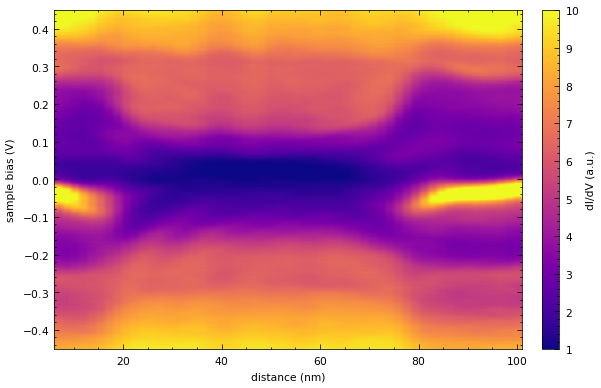

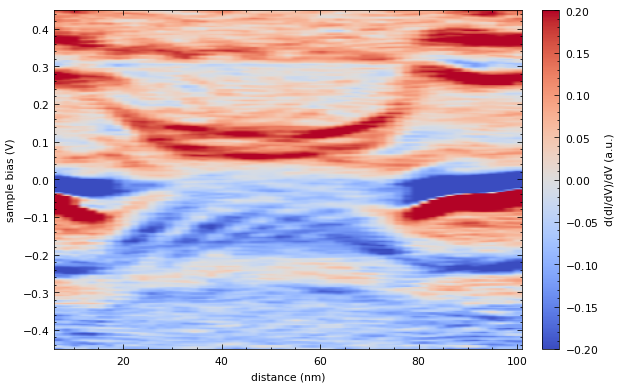

In [7]:
def plot_section(da, cmap, vmin, vmax, cbar_label, figsize=(6, 4), title=None):
    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(da.transpose('bias', 'dist').values, cmap=cmap, aspect='auto', origin='lower',
                   extent=extent_of(da, 'dist', 'bias'), vmin=vmin, vmax=vmax)
    ax.set_xlabel('distance (nm)')
    ax.set_ylabel('sample bias (V)')
    if title:
        ax.set_title(title, fontsize=8)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).set_label(cbar_label)
    return fig, ax


# panel a: normalized dI/dV
plot_section(sec_crop * 1000, 'plasma', 1, 10, 'dI/dV (a.u.)')
plt.show()
# panel b: derivative along the bias
plot_section(grad_crop, 'coolwarm', -0.2, 0.2, 'd(dI/dV)/dV (a.u.)')
plt.show()

## Panel d: line spectrum across a single domain wall

Line spectrum 267 (second 9 K session): mean over the repetitions and the sweep directions,
normalization to the mean of the first and last current values, a 7 × 7 running mean along
distance and bias, then the derivative along the bias. The window shown is 75-125 nm and
−0.3 to +0.025 V, as in the figure.

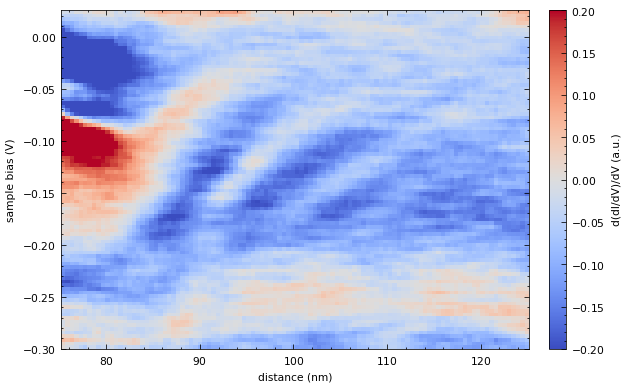

In [8]:
line_spec_267 = rhkpy.rhkdata(get_data('MK_ABC_FLG_25_9K_2023_10_28_05_15_50_267.sm4'))
ls_mean = line_spec_267.spectra.mean(dim=['repetitions', 'biasscandir'])
current_first = -ls_mean.current[0, :].data
current_last = ls_mean.current[-1, :].data
ls_norm = 2 * ls_mean / (current_first + current_last)
ls_norm_mean = ls_norm.rolling(dist=7, bias=7, center=True).mean()

CROP_267 = 3
lia_267 = ls_norm_mean.lia
grad_267 = lia_267.copy(data=np.gradient(lia_267.data * 1000, axis=lia_267.dims.index('bias')))
grad_267 = grad_267[CROP_267:-CROP_267, CROP_267:-CROP_267]
grad_267_crop = grad_267.sel(dist=slice(75, 125), bias=slice(-0.3, 0.025))

plot_section(grad_267_crop, 'coolwarm', -0.2, 0.2, 'd(dI/dV)/dV (a.u.)')
plt.show()

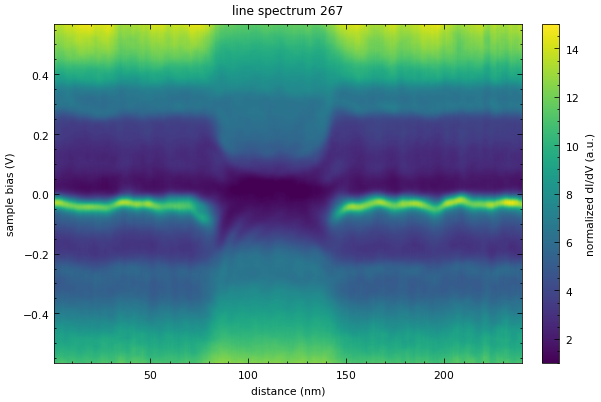

In [9]:
# the same line spectrum without the derivative, full range
plot_section(lia_267[CROP_267:-CROP_267, CROP_267:-CROP_267] * 1000, 'viridis', 1, 15,
             'normalized dI/dV (a.u.)', title='line spectrum 267')
plt.show()

## Panel c: scattering wave vectors on the tight-binding bands of (+⁴−)

The positions of two neighbouring fringe maxima (`strip1`, `strip2`, in nm) were read off the
derivative map of line spectrum 267 at each bias. Their spacing gives the backscattering wave vector
Δk = 2π/λ, plotted as k₀ ± Δk/2 around the Dirac point k₀ of the calculated bands. The bias of the
LDOS minimum is taken as the energy zero. The error bars are the FWHM of the Fourier peak at the
biases where it was measured. The distance axis carries the calibration from the atomic-resolution images.

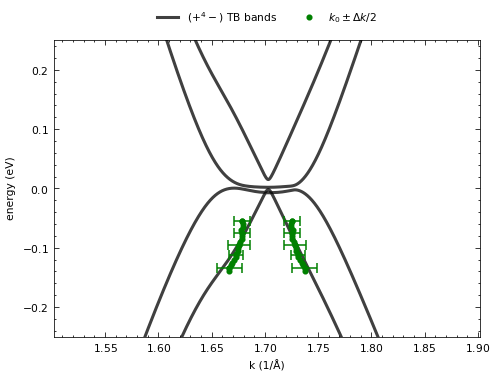

In [10]:
bias = np.array([-0.165, -0.160, -0.155, -0.150, -0.145, -0.140, -0.135, -0.130, -0.125,
                 -0.120, -0.115, -0.110, -0.105, -0.100, -0.095, -0.090, -0.085, -0.080])
strip1 = np.array([91.694, 92.365, 92.869, 93.372, 93.717, 94.071, 94.854, 95.203, 96.120,
                   96.510, 96.812, 97.552, 98.321, 98.899, 99.668, 100.053, 100.822, 101.977])
strip2 = np.array([100.938, 101.797, 102.769, 103.608, 104.615, 105.426, 106.209, 107.472, 108.167,
                   109.342, 109.929, 111.596, 112.366, 112.943, 113.257, 114.867, 115.829, 116.406])

MIN_LDOS = -0.025          # bias of the LDOS minimum, taken as the energy zero (V)
CALIBRATION = 246 / 260.5  # distance-axis calibration from the atomic-resolution images
K0 = 1.702                 # Dirac point of the calculated bands (1/A)


def k_pm(first, second):
    """k0 +/- half the backscattering wave vector (1/A) from a fringe spacing (nm)."""
    dk = (2 * np.pi / ((second - first) * CALIBRATION)) * 0.1   # 1/nm -> 1/A
    return K0 + dk / 2, K0 - dk / 2


E_exp = bias - MIN_LDOS
k_plus, k_minus = k_pm(strip1, strip2)

bias_measured = np.array([-0.080, -0.100, -0.120, -0.137, -0.160]) - MIN_LDOS
sigma_k = np.array([0.00750, 0.00767, 0.01040, 0.00677, 0.01178])   # FWHM of the Fourier peak (1/A)
idx = [np.argmin(np.abs(E_exp - b)) for b in bias_measured]
k_plus_meas, k_minus_meas = k_pm(strip1[idx], strip2[idx])

E_th = np.load(get_data('l_6_1b_relevant_bands.npy'))   # (k points, 12 bands), eV
lk = np.load(get_data('linear_k.npy'))
k_bands = lk + 1.534                                     # k axis of the calculation (1/A)

fig, ax = plt.subplots(figsize=(5, 3.5))
bands = ax.plot(k_bands, E_th, color='black', alpha=0.75, lw=2)
bands[0].set_label('$(+^4-)$ TB bands')
ax.plot(k_plus, E_exp, 'go', ms=3, label='$k_0 \\pm \\Delta k/2$')
ax.plot(k_minus, E_exp, 'go', ms=3)
for k in (k_plus_meas, k_minus_meas):
    ax.errorbar(k, bias_measured, xerr=sigma_k, fmt='go', ms=3, capsize=3)
ax.set_xlabel('k (1/Å)')
ax.set_ylabel('energy (eV)')
ax.set_ylim(-0.25, 0.25)
ax.set_xlim(K0 - 0.2, K0 + 0.2)
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=False)
plt.show()

### Group velocity of the Dirac band

The band on which the measured points lie is the one whose two branches around k₀ best
reproduce them; its group velocity is v = (1/ħ) dE/dk.

In [11]:
def k_of_E(band, side):
    m = k_bands >= K0 if side == '+' else k_bands < K0
    order = np.argsort(band[m])
    return np.interp(E_exp, band[m][order], k_bands[m][order])


def rms_to_data(band):
    return sum(np.sqrt(np.mean((k_of_E(band, side) - ref) ** 2))
               for side, ref in (('+', k_plus), ('-', k_minus)))


rms = [rms_to_data(E_th[:, j]) for j in range(E_th.shape[1])]
DIRAC_BAND = int(np.argmin(rms))
E_dirac = E_th[:, DIRAC_BAND]

HBAR_EVS = 6.582119569e-16
v_g = np.gradient(E_dirac, k_bands) * 1e-10 / HBAR_EVS   # eV*A -> m/s
window = (E_dirac >= E_exp.min()) & (E_dirac <= E_exp.max())
print(f'Dirac band: column {DIRAC_BAND} (rms {rms[DIRAC_BAND]:.4f} 1/A)')
print(f'|v_g| over the measured window: {np.abs(v_g[window]).mean():.2e} m/s')

Dirac band: column 4 (rms 0.0080 1/A)
|v_g| over the measured window: 4.95e+05 m/s


## Panels e, f: tight-binding LDOS along a line and its energy derivative

System 1 of the tight-binding line spectra: the (+⁴−) strip embedded in (+⁵) (Szendrő geometry).
The LDOS is smoothed with a Gaussian of 4 energy pixels (4 meV) along the energy axis only, the
derivative is taken along the energy axis, and the section is cropped to the window of the figure.

(1000, 1944) (1944,) (1000,)


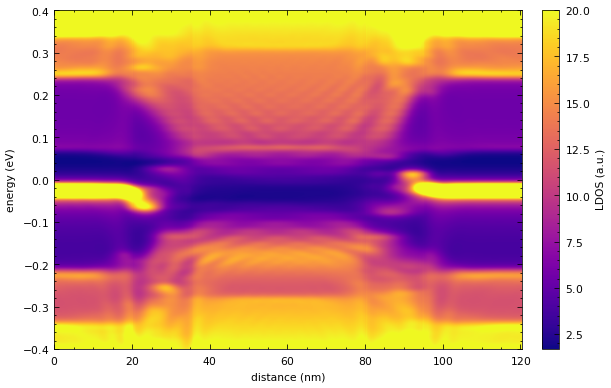

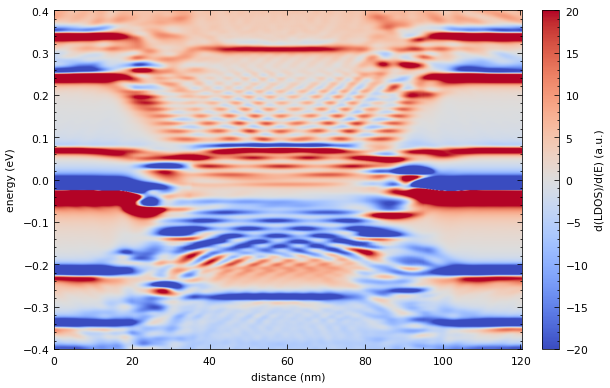

In [12]:
x = np.loadtxt(get_data('x_1_MARCI.txt'))              # Angstrom
ldos = np.loadtxt(get_data('ldos_1_MARCI.txt.gz'))     # (energy, x)
E_tb = np.loadtxt(get_data('TB_LS_E.txt'))             # eV
print(ldos.shape, x.shape, E_tb.shape)

Elim = 0.4
SIGMA = (4, 0)                                   # (sigma_E, sigma_x) in pixels
grad = np.gradient(ldos, E_tb, axis=0) * 100

x_mask = (x >= 550) & (x <= x.max() - 640)
E_mask = (E_tb >= -Elim) & (E_tb <= Elim)
dist_nm = (x[x_mask] - x[x_mask][0]) / 10
E_crop = E_tb[E_mask]
ldos_crop = gaussian_filter(ldos, sigma=SIGMA)[np.ix_(E_mask, x_mask)]
grad_crop_tb = gaussian_filter(grad, sigma=SIGMA)[np.ix_(E_mask, x_mask)]
extent_tb = extent_xy(dist_nm, E_crop)


def plot_tb(arr, cmap, vmin, vmax, cbar_label, figsize=(6, 4)):
    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(arr, cmap=cmap, aspect='auto', origin='lower', extent=extent_tb, vmin=vmin, vmax=vmax)
    ax.set_xlabel('distance (nm)')
    ax.set_ylabel('energy (eV)')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).set_label(cbar_label)
    return fig, ax


plot_tb(ldos_crop * 1000, 'plasma', None, 20, 'LDOS (a.u.)')       # panel e
plt.show()
plot_tb(grad_crop_tb, 'coolwarm', -20, 20, 'd(LDOS)/d(E) (a.u.)')   # panel f
plt.show()